*Step 1 — Data Understanding_Import libraries and load the dataset

In [109]:
# Import the libraries we need
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Find the main project folder
ROOT = Path.cwd()

# If we are inside the notebooks folder, go back one folder
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Set the file and folder locations
RAW = ROOT / "global_food_wastage_dataset_messy copy.xlsx"
DATA = ROOT / "data"
DOCS = ROOT / "docs"

# Create the output folders if needed
DATA.mkdir(parents=True, exist_ok=True)
DOCS.mkdir(parents=True, exist_ok=True)

# Check that the original file exists
assert RAW.exists(), f"File not found: {RAW}"

# Read the Excel dataset
df = pd.read_excel(RAW)

# Show the dataset shape
print("Dataset shape:", df.shape)

# Show the first five rows
display(df.head())

# Show column information
df.info()

# Show data types
display(df.dtypes)

Dataset shape: (5150, 8)


,Country,Year,Food Category,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Population (Million),Household Waste (%)
0,Australia,2021.0,Beverages,2967.07,2889.8,144.41,109.74,44.07
1,France,2021.0,Meat & Seafood,48643.30,45212.72,52.73,705.29,69.48
2,Brazil,2023.0,-,13744.82,14829.62,184.28,877.75,62.38
3,Saudi Arabia,2023.0,Frozen Food,1410.30,1386.31,NaN,1199.88,64.73
4,Indonesia,NaN,Bakery Items,47937.02,39218.6,164.71,953.46,38.55


<class 'pandas.DataFrame'>
RangeIndex: 5150 entries, 0 to 5149
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Country                    4736 non-null   str    
 1   Year                       4767 non-null   float64
 2   Food Category              4846 non-null   str    
 3   Total Waste (Tons)         4900 non-null   float64
 4   Economic Loss (Million $)  4753 non-null   object 
 5   Avg Waste per Capita (Kg)  4867 non-null   float64
 6   Population (Million)       4789 non-null   float64
 7   Household Waste (%)        4981 non-null   float64
dtypes: float64(5), object(1), str(2)
memory usage: 322.0+ KB


Country                          str
Year                         float64
Food Category                    str
Total Waste (Tons)           float64
Economic Loss (Million $)     object
Avg Waste per Capita (Kg)    float64
Population (Million)         float64
Household Waste (%)          float64
dtype: object

here we open the Excel file, checks how many rows and columns exist, and displays the data types. It helps us identify problems before making any changes.

*Create the data dictionary

In [110]:
# Describe each column in the dataset
dictionary = pd.DataFrame([
    ["Country", "Country name", "Text", "None"],
    ["Year", "Year of the record", "Integer", "Year"],
    ["Food Category", "Type of food", "Text", "None"],
    ["Total Waste (Tons)", "Total food waste", "Number", "Tons"],
    ["Economic Loss (Million $)", "Money lost from food waste", "Number", "Million USD"],
    ["Avg Waste per Capita (Kg)", "Average waste per person", "Number", "Kg per person"],
    ["Population (Million)", "Population value (removed during cleaning due to unreliable values)", "Number", "Million people"],
    ["Household Waste (%)", "Household waste percentage", "Number", "Percent"]


], columns=["Column", "Meaning", "Expected Type", "Unit"])

# Display the dictionary
display(dictionary)

# Save the dictionary in the docs folder
dictionary.to_csv(DOCS / "data_dictionary.csv", index=False)

,Column,Meaning,Expected Type,Unit
0,Country,Country name,Text,None
1,Year,Year of the record,Integer,Year
2,Food Category,Type of food,Text,None
3,Total Waste (Tons),Total food waste,Number,Tons
4,Economic Loss (Million $),Money lost from food waste,Number,Million USD
5,Avg Waste per Capita (Kg),Average waste per person,Number,Kg per person
6,Population (Million),Population value (removed during cleaning due ...,Number,Million people
7,Household Waste (%),Household waste percentage,Number,Percent


*Step 2 — Check Data Quality Before Cleaning
Create the quality-check functions

In [111]:
# Columns containing text
TEXT_COLS = ["Country", "Food Category"]

# Columns that should contain numbers
NUM_COLS = [
    "Year",
    "Total Waste (Tons)",
    "Economic Loss (Million $)",
    "Avg Waste per Capita (Kg)",
    "Population (Million)",
    "Household Waste (%)"
]

# Words or symbols used instead of missing values
PLACEHOLDERS = {
    "", "-", "unknown", "n/a",
    "na", "null", "none", "missing"
}

# Expected years in this dataset
YEAR_MIN = 2018
YEAR_MAX = 2024


# Check if a column contains placeholders
def placeholder_mask(series):
    values = series.astype("string").str.strip().str.lower()
    return series.notna() & values.isin(PLACEHOLDERS)


# Check for text that cannot be converted to numbers
def numeric_errors(series):
    numbers = pd.to_numeric(series, errors="coerce")

    return (
        series.notna()
        & ~placeholder_mask(series)
        & numbers.isna()
    )


# Check for impossible numerical values
def invalid_mask(data, column):
    x = pd.to_numeric(data[column], errors="coerce")

    if column == "Year":
        return x.notna() & (
            (x < YEAR_MIN) |
            (x > YEAR_MAX) |
            (x % 1 != 0)
        )

    if column == "Household Waste (%)":
        return x.notna() & ((x < 0) | (x > 100))

    if column in [
        "Total Waste (Tons)",
        "Economic Loss (Million $)"
    ]:
        return x.notna() & (x < 0)

    return x.notna() & (x <= 0)


# Use the IQR method to find unusual numbers
def iqr_mask(series):
    x = pd.to_numeric(series, errors="coerce")

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return x.notna() & ((x < lower) | (x > upper))


# Create a quality report for every column
def quality_report(data):
    results = []

    for column in data.columns:
        series = data[column]

        text_errors = 0

        if column in TEXT_COLS:
            normal = series.astype("string").str.strip().str.title()
            normal = normal.replace({
                "Usa": "USA",
                "Uk": "UK"
            })

            valid = series.notna() & ~placeholder_mask(series)

            text_errors = int(
                (valid & series.astype("string").ne(normal)).sum()
            )

        results.append({
            "Column": column,
            "Missing Values": int(series.isna().sum()),
            "Placeholders": int(placeholder_mask(series).sum()),
            "Wrong Number Format": (
                int(numeric_errors(series).sum())
                if column in NUM_COLS else 0
            ),
            "Text Problems": text_errors,
            "Invalid Values": (
                int(invalid_mask(data, column).sum())
                if column in NUM_COLS else 0
            ),
            "IQR Outliers": (
                int(iqr_mask(series).sum())
                if column in NUM_COLS and column != "Year" else 0
            )
        })

    return pd.DataFrame(results)

here we had created the reusable functions to find missing values, placeholders, incorrect numbers, text problems, impossible values, and statistical outliers.

*Run the before-cleaning checks

In [112]:
# Check the original dataset
before = quality_report(df)

# Count exact duplicate rows
before_duplicates = df.duplicated().sum()

# Display the results
print("Rows before cleaning:", len(df))
print("Exact duplicates:", before_duplicates)

display(before)

# Save the before-cleaning report
before.to_csv(DOCS / "quality_before.csv", index=False)

Rows before cleaning: 5150
Exact duplicates: 35


,Column,Missing Values,Placeholders,Wrong Number Format,Text Problems,Invalid Values,IQR Outliers
0,Country,414,62,0,184,0,0
1,Year,383,0,0,0,47,0
2,Food Category,304,63,0,191,0,0
3,Total Waste (Tons),250,0,0,0,49,25
4,Economic Loss (Million $),397,55,0,0,0,0
5,Avg Waste per Capita (Kg),283,0,0,0,48,32
6,Population (Million),361,0,0,0,47,26
7,Household Waste (%),169,0,0,0,0,0


now we measured the problems in the original dataset and saves the results before anything is changed


*Check duplicates and outliers visually

Examples of duplicate rows:


,Country,Year,Food Category,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Population (Million),Household Waste (%)
3,Saudi Arabia,2023.0,Frozen Food,1410.30,1386.31,NaN,1199.88,64.73
223,Australia,2018.0,Dairy Products,25698.19,29519.12,129.72,1215.20,35.96
259,Australia,2019.0,Meat & Seafood,31221.57,32289.6,23.32,1300.91,45.63
296,France,2023.0,Bakery Items,13901.18,11299.59,64.06,21.90,66.77
353,China,2018.0,Dairy Products,9960.73,11541.31,70.91,981.92,60.93
573,NaN,2018.0,Prepared Food,16184.37,13070.43,87.60,779.58,52.80
587,Japan,2019.0,Frozen Food,32065.24,36800.09,61.80,738.23,31.96
761,Spain,2019.0,Grains & Cereals,12625.72,11788.01,175.12,1009.26,40.52
791,Russia,2022.0,Fruits & Vegetables,9273.87,8570.01,126.89,1303.12,68.10
1098,Spain,2023.0,Fruits & Vegetables,29527.31,32708.12,177.67,871.21,57.64


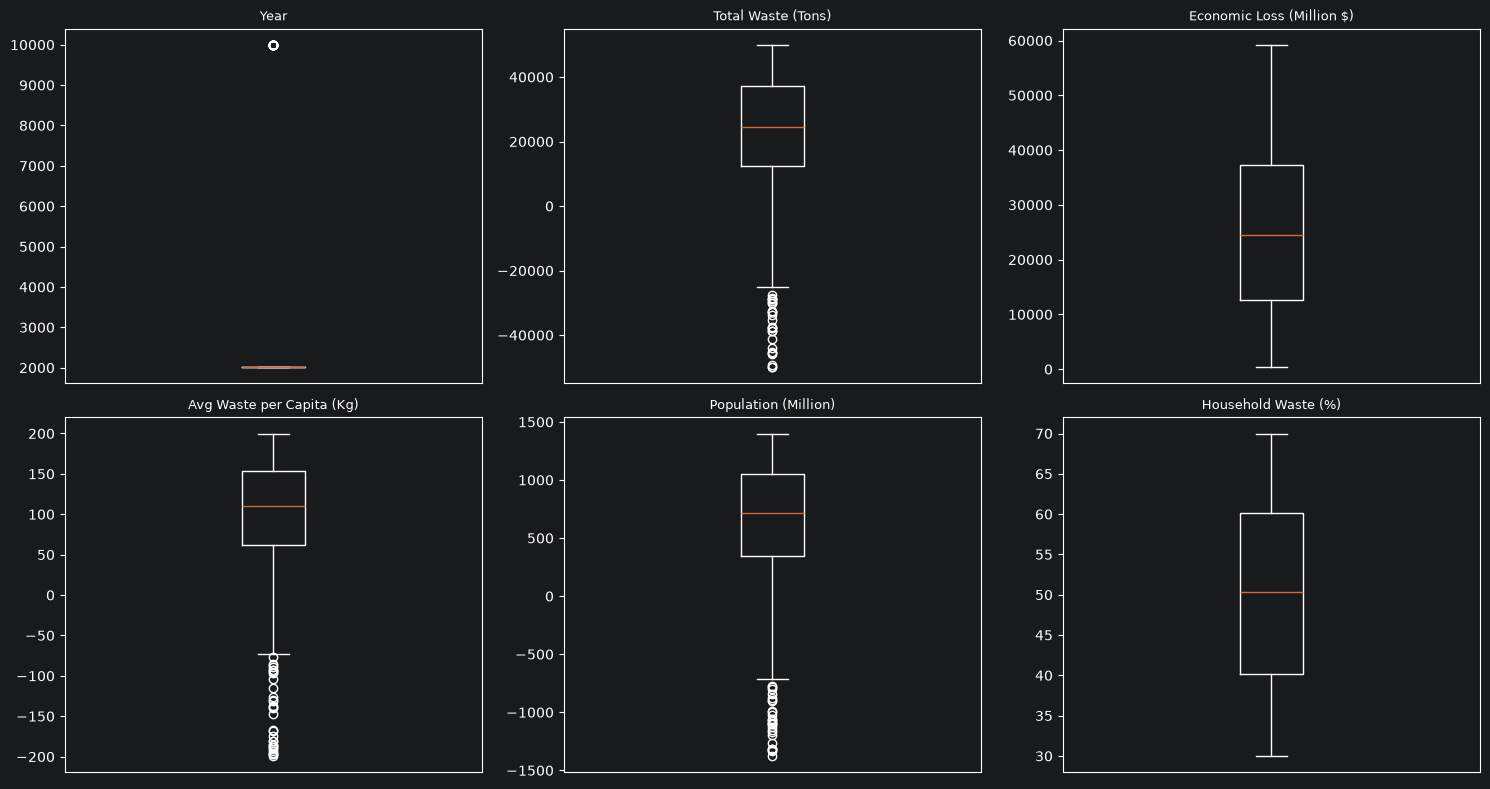

In [113]:
# Display examples of repeated rows
duplicates = df[df.duplicated(keep=False)]

print("Examples of duplicate rows:")
display(duplicates.head(10))

# Create boxplots for numerical columns
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flat, NUM_COLS):
    values = pd.to_numeric(df[column], errors="coerce").dropna()

    ax.boxplot(values)
    ax.set_title(column, fontsize=9)
    ax.tick_params(axis="x", bottom=False, labelbottom=False)

plt.tight_layout()
plt.show()

here it shows examples of duplicate records and creates boxplots to help us identify unusual values.

Step 3 — Clean the Dataset
Replace placeholders and clean text

In [114]:
# Make a copy so the original dataset stays unchanged
clean = df.copy()

# Replace placeholders with missing values
for column in clean.columns:
    mask = placeholder_mask(clean[column])
    clean.loc[mask, column] = np.nan

# Clean country and food category names
for column in TEXT_COLS:
    clean[column] = (
        clean[column]
        .astype("string")
        .str.strip()
        .str.title()
    )

# Keep common country abbreviations capitalized
for column in TEXT_COLS:
    clean[column] = clean[column].replace({
        "Usa": "USA",
        "Uk": "UK"
    })

print("Text cleaning completed.")
display(clean.head())

Text cleaning completed.


,Country,Year,Food Category,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Population (Million),Household Waste (%)
0,Australia,2021.0,Beverages,2967.07,2889.8,144.41,109.74,44.07
1,France,2021.0,Meat & Seafood,48643.30,45212.72,52.73,705.29,69.48
2,Brazil,2023.0,<NA>,13744.82,14829.62,184.28,877.75,62.38
3,Saudi Arabia,2023.0,Frozen Food,1410.30,1386.31,NaN,1199.88,64.73
4,Indonesia,NaN,Bakery Items,47937.02,39218.6,164.71,953.46,38.55


for this step we changed placeholders into real missing values, removes extra spaces, and makes text labels consistent.

*Convert numbers and handle invalid values

In [115]:
# Convert numerical columns into numbers
for column in NUM_COLS:
    clean[column] = pd.to_numeric(
        clean[column],
        errors="coerce"
    )

# Count invalid values before changing them
invalid_counts = {}

# Replace impossible numbers with missing values
for column in NUM_COLS:
    mask = invalid_mask(clean, column)

    invalid_counts[column] = int(mask.sum())

    clean.loc[mask, column] = np.nan

print("Invalid values found:")
print(invalid_counts)

print("Numerical cleaning completed.")

Invalid values found:
{'Year': 47, 'Total Waste (Tons)': 49, 'Economic Loss (Million $)': 0, 'Avg Waste per Capita (Kg)': 48, 'Population (Million)': 47, 'Household Waste (%)': 0}
Numerical cleaning completed.


we converted numbers stored as text into numeric values. Impossible values, such as negative waste or year 9999, become missing values instead of being replaced with guessed numbers.

*Remove duplicates and rows with missing required information

In [116]:
# Count rows before removing duplicates
rows_before_duplicates = len(clean)

# Remove exact duplicate records
clean = clean.drop_duplicates().copy()

# Calculate how many duplicate rows were removed
removed_duplicates = rows_before_duplicates - len(clean)

# These columns are required for the regression dataset
required = [
    "Economic Loss (Million $)",
    "Country",
    "Food Category",
    "Year"
]

# Find rows with missing required information
missing_required = clean[required].isna().any(axis=1)

# Count how many rows will be removed
removed_required = int(missing_required.sum())

# Keep only rows with complete required information
clean = clean.loc[~missing_required].copy()

# Convert Year to integer
clean["Year"] = clean["Year"].astype(int)

# Reset row numbers
clean = clean.reset_index(drop=True)

print("Original rows:", len(df))
print("Duplicates removed:", removed_duplicates)
print("Rows removed for missing required values:", removed_required)
print("Rows after cleaning:", len(clean))

display(clean.head())

Original rows: 5150
Duplicates removed: 48
Rows removed for missing required values: 1522
Rows after cleaning: 3580


,Country,Year,Food Category,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Population (Million),Household Waste (%)
0,Australia,2021,Beverages,2967.07,2889.80,144.41,109.74,44.07
1,France,2021,Meat & Seafood,48643.30,45212.72,52.73,705.29,69.48
2,Saudi Arabia,2023,Frozen Food,1410.30,1386.31,NaN,1199.88,64.73
3,UK,2023,Bakery Items,18014.05,15852.44,180.34,NaN,61.14
4,Japan,2018,Bakery Items,27534.23,29110.52,162.58,693.46,69.77


we removed exact duplicate records and rows missing the regression target or essential country, category, and year information.

In [117]:
# Check duplicate counts
print("Duplicates in original data:", df.duplicated().sum())
print("Duplicates removed during cleaning:", removed_duplicates)
print("Duplicates remaining:", clean.duplicated().sum())

Duplicates in original data: 35
Duplicates removed during cleaning: 48
Duplicates remaining: 0


In [118]:
# Check whether cleaning created additional duplicate matches
print("Original exact duplicates:", before_duplicates)
print("Duplicates removed after standardization:", removed_duplicates)

additional_duplicates = removed_duplicates - before_duplicates

print("Difference:", additional_duplicates)

Original exact duplicates: 35
Duplicates removed after standardization: 48
Difference: 13


In [119]:
# Numerical predictors kept for regression
predictors = [
    "Total Waste (Tons)",
    "Avg Waste per Capita (Kg)",
    "Household Waste (%)"
]

# Check missing predictor values
print("Missing predictor values:")
display(clean[predictors].isna().sum())

# Missing predictor values will be handled during modeling
# using an imputer fitted only on training data

Missing predictor values:


Total Waste (Tons)           220
Avg Waste per Capita (Kg)    229
Household Waste (%)          116
dtype: int64

here It shows the missing predictor values that remain. These will be handled after splitting the data into training and testing sets to avoid data leakage.

*Check unrealistic population values

In [120]:
# Check duplicates after removing Population
print("Duplicates before:", clean.duplicated().sum())

# Remove duplicate rows
clean = clean.drop_duplicates().reset_index(drop=True)

print("Duplicates after:", clean.duplicated().sum())
print("Final rows:", len(clean))
# Show the largest population values
population_check = clean[
    ["Country", "Year", "Population (Million)"]
].sort_values(
    by="Population (Million)",
    ascending=False
)

display(population_check.head(15))

# Show population values for France and Saudi Arabia
countries_to_check = ["France", "Saudi Arabia"]

display(
    clean.loc[
        clean["Country"].isin(countries_to_check),
        ["Country", "Year", "Population (Million)"]
    ].sort_values(["Country", "Year"]).head(20)
)

Duplicates before: 0
Duplicates after: 0
Final rows: 3580


,Country,Year,Population (Million)
3109,UK,2019,1399.97
616,India,2021,1398.61
1547,China,2023,1398.60
912,Spain,2022,1398.58
1279,Mexico,2019,1397.75
178,Spain,2021,1396.92
2725,Germany,2024,1396.52
1063,Saudi Arabia,2023,1395.67
2015,Australia,2024,1395.51
3019,Germany,2022,1395.33


,Country,Year,Population (Million)
40,France,2018,596.51
114,France,2018,477.47
209,France,2018,855.40
237,France,2018,93.06
256,France,2018,104.72
628,France,2018,446.58
669,France,2018,1276.31
855,France,2018,1187.66
949,France,2018,466.49
1134,France,2018,1376.28


It helps us identify unrealistic population values. For example, values around 705 million for France or 1,199 million for Saudi Arabia are not credible real-world population figures.

In [121]:
# Count suspicious population values before dropping the column
unrealistic_population_count = int(
    (clean["Population (Million)"] > 500).sum()
)

print("Population values above 500 million:",
      unrealistic_population_count)

# Drop Population because its values are not reliable
clean = clean.drop(columns=["Population (Million)"])

# Check duplicates after dropping Population
duplicates_after_drop = clean.duplicated().sum()
print("Duplicates after dropping Population:", duplicates_after_drop)

# Remove duplicate rows
clean = clean.drop_duplicates().reset_index(drop=True)

# Confirm the final results
print("Duplicates remaining:", clean.duplicated().sum())
print("Final number of rows:", len(clean))
print("Final number of columns:", len(clean.columns))

Population values above 500 million: 2143
Duplicates after dropping Population: 5
Duplicates remaining: 0
Final number of rows: 3575
Final number of columns: 7


*Check Unrealistic Population Values.

In [122]:
# Check population values before removing the column
if "Population (Million)" in clean.columns:

    population_check = clean[
        ["Country", "Year", "Population (Million)"]
    ].sort_values(
        by="Population (Million)",
        ascending=False
    )

    display(population_check.head(15))

else:
    print("Population column has already been removed.")

Population column has already been removed.


here we identify unrealistic population values. For example, values around 705 million for France or 1,199 million for Saudi Arabia are not credible real-world population figures.

*Step 4 — Compare Before and After Cleaning

In [123]:
# Check the cleaned dataset using the same functions
after = quality_report(clean)

# Count duplicates after cleaning
after_duplicates = int(clean.duplicated().sum())

print("Rows after cleaning:", len(clean))
print("Duplicates after cleaning:", after_duplicates)

display(after)

# Save the after-cleaning report
after.to_csv(DOCS / "quality_after.csv", index=False)

Rows after cleaning: 3575
Duplicates after cleaning: 0


,Column,Missing Values,Placeholders,Wrong Number Format,Text Problems,Invalid Values,IQR Outliers
0,Country,0,0,0,0,0,0
1,Year,0,0,0,0,0,0
2,Food Category,0,0,0,0,0,0
3,Total Waste (Tons),220,0,0,0,0,0
4,Economic Loss (Million $),0,0,0,0,0,0
5,Avg Waste per Capita (Kg),229,0,0,0,0,0
6,Household Waste (%),116,0,0,0,0,0


*Create the comparison table

In [124]:
# List the quality measures
metrics = [
    "Missing Values",
    "Placeholders",
    "Wrong Number Format",
    "Text Problems",
    "Invalid Values",
    "IQR Outliers"
]

# Create the summary table
summary = pd.DataFrame({
    "Issue": ["Rows", "Exact Duplicates"] + metrics,

    "Before": [
        len(df),
        int(before_duplicates)
    ] + [int(before[m].sum()) for m in metrics],

    "After": [
        len(clean),
        after_duplicates
    ] + [int(after[m].sum()) for m in metrics]
})

# Calculate the change
summary["Change"] = summary["After"] - summary["Before"]

# Display and save the comparison
display(summary)

summary.to_csv(
    DOCS / "quality_summary.csv",
    index=False
)

# Calculate the percentage of removed rows
removed_rows = len(df) - len(clean)
removed_percent = (removed_rows / len(df)) * 100

print("Rows removed:", removed_rows)
print(f"Percentage removed: {removed_percent:.2f}%")

# Explain how to interpret the IQR results
print(
    "IQR counts can change because cleaning changes "
    "the data distribution and the quartile boundaries."
)

,Issue,Before,After,Change
0,Rows,5150,3575,-1575
1,Exact Duplicates,35,0,-35
2,Missing Values,2561,565,-1996
3,Placeholders,180,0,-180
4,Wrong Number Format,0,0,0
5,Text Problems,375,0,-375
6,Invalid Values,191,0,-191
7,IQR Outliers,83,0,-83


Rows removed: 1575
Percentage removed: 30.58%
IQR counts can change because cleaning changes the data distribution and the quartile boundaries.


We compared the quality of the original and cleaned datasets and calculated how many rows were removed

*Save the cleaning decisions table

In [125]:
# Record the cleaning actions and explain their impact on regression
decisions = pd.DataFrame([
    [
        "Missing values and placeholders",
        int(before["Missing Values"].sum()
            + before["Placeholders"].sum()),
        "Replace placeholders with NaN and handle missing required fields",
        "Placeholders like 'unknown' or '-' are not real measurements. "
        "If the regression treats them as data, it learns patterns from "
        "fabricated values and its predictions of Economic Loss become "
        "unreliable."
    ],
    [
        "Duplicate rows",
        removed_duplicates,
        "Remove duplicate records",
        "Duplicate rows give the same observation extra weight during "
        "training, so the regression overfits to those records and the "
        "learned coefficients no longer reflect the true relationship "
        "between the predictors and Economic Loss."
    ],
    [
        "Text problems",
        int(before["Text Problems"].sum()),
        "Remove spaces and fix capitalization",
        "If 'France' and 'france ' stay as different labels, one-hot "
        "encoding splits the same country into two columns, each with "
        "half the rows. The regression then estimates two weaker country "
        "effects instead of one reliable effect on Economic Loss."
    ],
    [
        "Wrong number formats",
        int(before["Wrong Number Format"].sum()),
        "Convert values to numbers",
        "A regression can only compute with numeric inputs. Text in a "
        "numeric column would either be dropped or cause an error, so "
        "the affected rows could not contribute to predicting Economic "
        "Loss."
    ],
    [
        "Invalid numbers",
        sum(invalid_counts.values()),
        "Replace impossible values with NaN",
        "Negative waste or a household share above 100% cannot occur in "
        "reality. Left in, they pull the regression line toward "
        "impossible relationships and distort the predicted loss for "
        "otherwise valid rows."
    ],
    [
        "Missing required information",
        removed_required,
        "Remove affected rows",
        "A row without Economic Loss has no target value, so supervised "
        "regression cannot learn from it. A row without Country or Food "
        "Category cannot be encoded, so it would either crash the model "
        "or be silently dropped later."
    ],
    [
        "IQR outlier flags",
        int(before["IQR Outliers"].sum()),
        "Review unusual values without automatic removal",
        "Some flagged values may be genuine (large countries genuinely "
        "waste more). Removing them automatically would bias the "
        "regression toward mid-sized cases and make the model "
        "under-predict loss for the largest countries."
    ],
    [
        "Unrealistic population values",
        unrealistic_population_count,
        "Drop Population (Million) entirely",
        "The same country and year appears with many different "
        "population values (e.g., France ranges from 93 to 1,376 "
        "million within the same year), some values are negative, and "
        "a single threshold cannot separate realistic values for large "
        "countries from impossible values for small ones. Left in, the "
        "regression would learn from fabricated values and could output "
        "misleading country-level loss estimates."
    ]
], columns=[
    "Issue",
    "How Many",
    "What We Did",
    "Why"
])

# Display the cleaning decisions
display(decisions)

# Save the cleaning decisions
decisions.to_csv(
    DOCS / "cleaning_decisions.csv",
    index=False
)

,Issue,How Many,What We Did,Why
0,Missing values and placeholders,2741,Replace placeholders with NaN and handle missi...,Placeholders like 'unknown' or '-' are not rea...
1,Duplicate rows,48,Remove duplicate records,Duplicate rows give the same observation extra...
2,Text problems,375,Remove spaces and fix capitalization,If 'France' and 'france ' stay as different la...
3,Wrong number formats,0,Convert values to numbers,A regression can only compute with numeric inp...
4,Invalid numbers,191,Replace impossible values with NaN,Negative waste or a household share above 100%...
5,Missing required information,1522,Remove affected rows,A row without Economic Loss has no target valu...
6,IQR outlier flags,83,Review unusual values without automatic removal,Some flagged values may be genuine (large coun...
7,Unrealistic population values,2143,Drop Population (Million) entirely,The same country and year appears with many di...


*Step 5 — Save and Validate the Cleaned Dataset

In [126]:
# Check that the cleaned dataset has seven columns
assert len(clean.columns) == 7

# Check that Population and Population_Flag were removed
assert "Population (Million)" not in clean.columns
assert "Population_Flag" not in clean.columns

# Check that no exact duplicates remain
assert clean.duplicated().sum() == 0

# Check that required columns have no missing values
assert clean[required].isna().sum().sum() == 0

# Check that no invalid numerical values remain
# Only check columns that still exist
for column in NUM_COLS:
    if column in clean.columns:
        assert invalid_mask(clean, column).sum() == 0

# Check that placeholders were removed
for column in clean.columns:
    assert placeholder_mask(clean[column]).sum() == 0

# Check that Economic Loss is numerical
assert pd.api.types.is_numeric_dtype(
    clean["Economic Loss (Million $)"]
)

# Save the cleaned dataset
output_file = DATA / "cleaned_food_waste.csv"

clean.to_csv(output_file, index=False)

# Read the saved file to confirm it works
saved_data = pd.read_csv(output_file)

assert saved_data.shape == clean.shape

print("All checks passed!")
print("Cleaned dataset saved:", output_file)
print("Quality reports saved:", DOCS)

# Display the final dataset
display(saved_data.head())

All checks passed!
Cleaned dataset saved: /Users/maryamalhosani/Downloads/data/cleaned_food_waste.csv
Quality reports saved: /Users/maryamalhosani/Downloads/docs


,Country,Year,Food Category,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Household Waste (%)
0,Australia,2021,Beverages,2967.07,2889.80,144.41,44.07
1,France,2021,Meat & Seafood,48643.30,45212.72,52.73,69.48
2,Saudi Arabia,2023,Frozen Food,1410.30,1386.31,NaN,64.73
3,UK,2023,Bakery Items,18014.05,15852.44,180.34,61.14
4,Japan,2018,Bakery Items,27534.23,29110.52,162.58,69.77
